# Proyecto DAM — Cuaderno de análisis del detector de intrusiones

Este cuaderno **ya está escrito**: tu trabajo no es programarlo, sino **entenderlo, ponerlo a prueba y criticarlo**.

**Cómo usarlo**

1. Antes de empezar, genera tus datos en la terminal (usa tu número de lista como semilla):
   `python generar_logs.py --seed <tu_numero> --salida auth.log --etiquetas etiquetas.csv`
2. Ejecuta las celdas **en orden** (Mayús + Intro).
3. Las celdas marcadas con ❓ son preguntas: escribe tu respuesta en la celda de texto que hay debajo (doble clic para editarla).
4. Las celdas marcadas con 🧪 son experimentos: cambia **solo** el valor indicado, ejecuta y anota el resultado en la tabla final.

![Diagrama de flujo del sistema](docs/diagrama_flujo.png)

## 0. Preparación

In [97]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from logtools import cargar_etiquetas, cargar_log, construir_features

RUTA_LOG = "auth.log"
RUTA_ETIQUETAS = "etiquetas.csv"

## 1. Del texto del log a una tabla

La función `cargar_log` (en `logtools.py`) lee cada línea del fichero, extrae sus datos con expresiones regulares y los guarda en un `DataFrame`.

In [98]:
df = cargar_log(RUTA_LOG)
df.head(10)

14391 eventos cargados; 0 lineas ignoradas


,timestamp,tipo,usuario,ip,puerto,usuario_invalido
0,2026-10-07 00:03:00,acceso_ok,backup,10.0.0.5,33150,False
1,2026-10-07 00:04:02,usuario_invalido,git,203.0.113.174,57438,True
2,2026-10-07 00:04:02,fallo_password,git,203.0.113.174,57438,True
3,2026-10-07 00:04:05,usuario_invalido,guest,203.0.113.174,60629,True
4,2026-10-07 00:04:05,fallo_password,guest,203.0.113.174,60629,True
5,2026-10-07 00:04:05,conexion_cerrada,root,203.0.113.174,36541,False
6,2026-10-07 00:04:06,usuario_invalido,oracle,203.0.113.174,59533,True
7,2026-10-07 00:04:06,fallo_password,oracle,203.0.113.174,59533,True
8,2026-10-07 00:04:08,usuario_invalido,guest,203.0.113.174,35147,True
9,2026-10-07 00:04:08,fallo_password,guest,203.0.113.174,35147,True


In [99]:
df["tipo"].value_counts()

tipo
fallo_password      6714
usuario_invalido    5884
conexion_cerrada    1105
acceso_ok            688
Name: count, dtype: int64

❓ **P1.** ¿Qué representa cada fila de `df`? ¿Qué columnas tiene y qué significa cada una?

**Tu respuesta:** Cada fila de `df` es un evento del log de autenticación del servidor, es decir, una línea de `auth.log` que el programa ha leído y convertido en datos. Tiene seis columnas:

- `timestamp`: fecha y hora en que ocurrió el evento.
- `tipo`: qué pasó. Puede ser `acceso_ok` (alguien entró bien), `fallo_password` (contraseña incorrecta), `usuario_invalido` (el usuario no existe en el servidor) o `conexion_cerrada` (la conexión se cierra durante la autenticación).
- `usuario`: el nombre de usuario con el que se intentó entrar (`root`, `git`, `guest`, `backup`...).
- `ip`: la dirección desde la que se conecta. Es lo más importante, porque después el modelo clasifica IPs.
- `puerto`: el puerto de origen de esa conexión.
- `usuario_invalido`: `True` si el usuario no existe en el servidor y `False` si existe.

Ejemplo: la fila 0 es un acceso correcto de `backup` desde `10.0.0.5`, una IP interna, que es uso normal. En cambio, las filas 1 a 9 son de `203.0.113.174`: en solo 6 segundos prueba `git`, `guest`, `root` y `oracle`, casi todos inexistentes. Además, cada intento genera dos filas casi iguales (un `usuario_invalido` y un `fallo_password`), porque sshd escribe dos líneas por intento.

❓ **P2.** Abre `logtools.py` y localiza `PATRON_LINEA`. Explica con tus palabras qué trozo de la línea captura cada parte con nombre (`mes`, `dia`, `hora`, `host`, `pid`, `msg`).

**Tu respuesta:** `PATRON_LINEA` es una expresión regular que reconoce la estructura que tienen todas las líneas del log y separa sus partes. Con una línea como `Oct  7 00:04:02 srv-web01 sshd[2301]: Invalid user git from 203.0.113.174 port 57438`:

- `mes` captura `Oct`, el mes en tres letras.
- `dia` captura `7`, el día del mes (una o dos cifras).
- `hora` captura `00:04:02`, la hora exacta en formato HH:MM:SS.
- `host` captura `srv-web01`, el nombre del servidor que escribe el log.
- `pid` captura `2301`, el número de proceso de sshd (lo que va entre corchetes).
- `msg` captura todo lo que viene después de `sshd[...]: `, que es el mensaje en sí. Ese texto se analiza después con otros patrones (`PATRONES_MSG`) para sacar el tipo de evento, el usuario, la IP y el puerto.

Si una línea no encaja con el patrón, `parsear_linea` devuelve `None` y se cuenta como línea ignorada.

❓ **P3.** El log de syslog no trae el año. ¿Cómo lo resuelve el código y qué problema podría dar con un log que cruce el 31 de diciembre?

**Tu respuesta:** Las líneas de syslog solo traen mes, día y hora, así que el código usa un año fijo: la constante `ANIO = 2026`, que `parsear_linea` pasa a `datetime` para construir cada `timestamp`.

El problema aparece si el log cruza el 31 de diciembre: todas las líneas se fecharían en 2026, de modo que las de enero quedarían como enero de 2026, casi un año antes que las de diciembre. Los eventos quedarían desordenados y fallarían las características que dependen del tiempo: `duracion_min` saldría negativa o enorme y `max_fallos_5min`, que usa una ventana deslizante de 5 minutos sobre los timestamps, se calcularía mal. Habría que detectar el salto de diciembre a enero y sumar un año a partir de ahí.

## 2. Características por IP

Un modelo de IA no entiende líneas de texto: necesita **una fila de números por cada cosa que queremos clasificar**. Aquí clasificamos direcciones IP, así que `construir_features` resume lo que ha hecho cada IP.

In [100]:
X = construir_features(df)
X.head()

,n_eventos,n_fallos,n_ok,n_usuarios,n_inv,duracion_min,ratio_fallos,fallos_por_min,es_interna,max_fallos_5min,hora_media
ip,,,,,,,,,,,
10.0.0.5,24,0,24,1,0,1380.000000,0.0,0.000000,1,0,11.500000
10.0.1.1,2,1,1,1,0,0.166667,0.5,1.000000,1,1,13.000000
10.0.1.10,3,0,3,1,0,207.200000,0.0,0.000000,1,0,14.333333
10.0.1.11,5,3,2,1,0,209.383333,0.6,0.014328,1,2,11.000000
10.0.1.12,2,0,2,1,0,64.216667,0.0,0.000000,1,0,13.500000


In [101]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
n_eventos,384.0,37.476562,102.101595,1.0,3.000000,4.000000,10.000000,561.000000
n_fallos,384.0,17.484375,46.320935,0.0,0.000000,2.000000,7.000000,250.000000
n_ok,384.0,1.791667,1.750295,0.0,1.000000,2.000000,3.000000,24.000000
n_usuarios,384.0,2.851562,3.783480,1.0,1.000000,1.000000,1.000000,12.000000
n_inv,384.0,30.645833,93.532807,0.0,0.000000,0.000000,0.000000,500.000000
duracion_min,384.0,285.420573,355.024751,0.0,3.104167,191.825000,409.475000,1431.500000
ratio_fallos,384.0,0.363107,0.316737,0.0,0.000000,0.443001,0.529412,1.000000
fallos_por_min,384.0,4.228413,11.816989,0.0,0.000000,0.007941,0.126960,46.744186
es_interna,384.0,0.687500,0.464117,0.0,0.000000,1.000000,1.000000,1.000000
max_fallos_5min,384.0,14.895833,44.186403,0.0,0.000000,1.000000,3.000000,218.000000


❓ **P4.** ¿Qué representa ahora cada fila? ¿Por qué se agrupa por IP y no por usuario o por evento?

**Tu respuesta:** Cada fila de `X` es una IP resumida con números sobre todo lo que ha hecho en el log (eventos, fallos, usuarios distintos, duración, velocidad...). Hay 384 IPs. Por ejemplo, `10.0.0.5` tiene 24 eventos, todos accesos correctos, y `10.0.1.1` solo 2 con 1 fallo.

Se agrupa por IP porque lo que hay que decidir es qué IP es atacante, y la IP es lo que un administrador puede bloquear. Un solo evento no basta (un fallo de contraseña es normal) y por usuario no se vería el ataque, porque el atacante prueba muchos usuarios distintos desde la misma IP.

❓ **P5.** Antes de mirar los resultados del modelo, elige **tres características** que creas que mejor distinguen a un atacante de un usuario normal y justifica por qué.

**Tu respuesta:**

1. `max_fallos_5min`: un atacante lanza muchos intentos seguidos y una persona normal falla una o dos veces. La mediana es 1 y el máximo 218.
2. `n_inv`: un usuario legítimo conoce su nombre de usuario, así que casi nunca prueba usuarios inexistentes. La mediana es 0 y el máximo 500.
3. `es_interna`: los ataques suelen venir de fuera de la red de la organización, así que una IP externa con muchos fallos es más sospechosa.

## 3. ¿Cuántos atacantes hay y en qué se diferencian?

In [102]:
y = cargar_etiquetas(RUTA_ETIQUETAS, X.index)
print(y.value_counts().rename({0: "legítimas", 1: "atacantes"}))
print(f"Proporción de atacantes: {y.mean():.0%}")

etiqueta
legítimas    284
atacantes    100
Name: count, dtype: int64
Proporción de atacantes: 26%


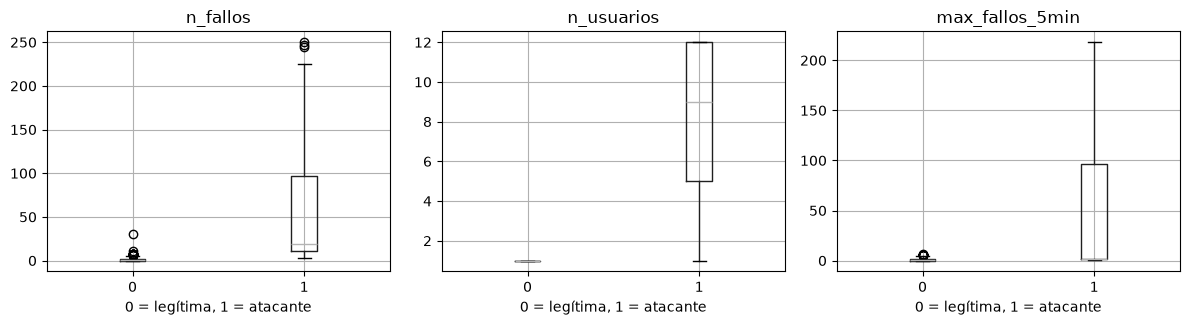

In [103]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.5))
for eje, col in zip(ejes, ["n_fallos", "n_usuarios", "max_fallos_5min"]):
    X.assign(etiqueta=y).boxplot(column=col, by="etiqueta", ax=eje)
    eje.set_title(col)
    eje.set_xlabel("0 = legítima, 1 = atacante")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [104]:
X.assign(etiqueta=y).groupby("etiqueta")[["n_inv", "es_interna"]].mean()

,n_inv,es_interna
etiqueta,,
0,0.00,0.890845
1,117.68,0.110000


❓ **P6.** ¿Coinciden las tres características que elegiste en P5 con lo que ves en los gráficos? ¿Alguna te ha sorprendido?

**Tu respuesta:** Hay 284 IPs legítimas y 100 atacantes (un 26 %). De mis tres características, los gráficos solo muestran `max_fallos_5min`, y coincide con lo que esperaba: en las legítimas está cerca de 0 y en los atacantes llega a más de 200. Me sorprendió que la caja de los atacantes es muy ancha y su mediana baja, así que hay atacantes con pocos fallos seguidos que esta característica sola no detectaría. De `n_inv` y `es_interna` no puedo decir nada porque no se dibujan.

Lo que más me sorprendió fue `n_usuarios`, que no elegí: todas las legítimas tienen exactamente 1 usuario y los atacantes entre 5 y 12 (mediana 9), así que separa los dos grupos casi sin solaparse. Tiene sentido: una persona usa su cuenta, un atacante prueba muchos nombres.

❓ **P7.** Hay IPs legítimas con muchos fallos y atacantes con pocos. Localiza al menos un caso de cada tipo en `X` (pista: `X[(y == 0) & (X["n_fallos"] > 10)]`) y explica por qué engañan a una regla sencilla.

**Tu respuesta:** Hay IPs legítimas con muchos fallos y atacantes con pocos. Localiza al menos un caso de cada tipo en X y explica por qué engañan a una regla sencilla.
Una IP legítima con muchos fallos es 192.168.1.249, que tiene 31 fallos de contraseña. Corresponde a un script de monitorización mal configurado, por lo que puede parecer un ataque aunque sea una IP legítima.

Un atacante con pocos fallos es 203.0.113.128, que solo tiene 3 fallos. Una regla que considere sospechosas únicamente las IPs con muchos fallos podría no detectarlo.

Esto demuestra que no basta con contar los fallos: hay que tener en cuenta otras características, como los usuarios diferentes que se prueban, la duración y la velocidad de los intentos.

## 4. Entrenar y evaluar el modelo

Se reserva un 25 % de las IPs para **examinar** el modelo con datos que no ha visto durante el entrenamiento.

In [105]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))

[[71  0]
 [ 0 25]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        71
           1      1.000     1.000     1.000        25

    accuracy                          1.000        96
   macro avg      1.000     1.000     1.000        96
weighted avg      1.000     1.000     1.000        96



❓ **P8.** Lee la matriz de confusión: ¿cuántos usuarios legítimos habrían sido bloqueados por error (falsos positivos)? ¿Y cuántos atacantes se han colado (falsos negativos)? ¿Qué error es más grave en un servidor real y por qué?

**Tu respuesta:** La matriz de confusión es: 
[[71  0]
 [ 0 25]]

 - Falsos positivos: 0. Ningún usuario legítimo ha sido clasificado como atacante.
 - Falsos negativos: 0. Ningún atacante ha sido clasificado como legítimo.

En un servidor real, los falsos negativos pueden ser especialmente graves porque permiten que un atacante pase desapercibido. Sin embargo, los falsos positivos también son importantes porque pueden bloquear a usuarios legítimos y dificultar su trabajo.


❓ **P9.** ¿Qué hacen `stratify=y` y `class_weight="balanced"`? ¿Qué pasaría sin ellos?

**Tu respuesta:** stratify=y hace que los conjuntos de entrenamiento y prueba mantengan aproximadamente la misma proporción de IPs legítimas y atacantes que los datos originales.

class_weight="balanced" da más importancia a la clase que tiene menos ejemplos, en este caso los atacantes, para evitar que el modelo se centre demasiado en reconocer las IPs legítimas.

Sin ellos, el reparto podría quedar desequilibrado y el modelo podría aprender peor a detectar atacantes, especialmente porque hay menos atacantes que IPs legítimas.

❓ **P10.** ¿Por qué se evalúa con IPs que el modelo no ha visto al entrenar? ¿Qué podría ocurrir si evaluáramos con las mismas?

**Tu respuesta:** Se utilizan IPs diferentes para comprobar si el modelo realmente ha aprendido a distinguir entre usuarios legítimos y atacantes.

Si se evaluara con las mismas IPs utilizadas durante el entrenamiento, el resultado podría ser demasiado bueno porque el modelo ya habría aprendido sus características. Esto daría una impresión equivocada de su capacidad para detectar amenazas nuevas.

Por eso se reserva una parte de los datos para realizar una prueba independiente.

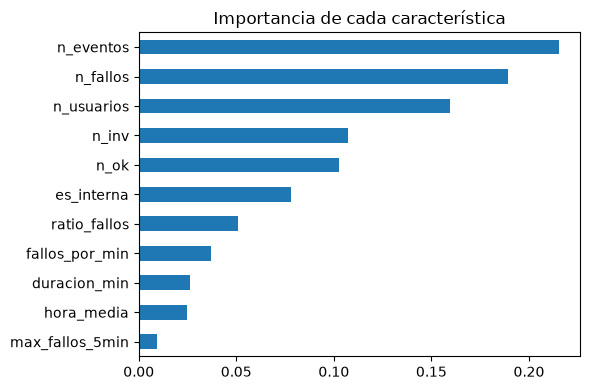

In [106]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(figsize=(6, 4), title="Importancia de cada característica")
plt.tight_layout()
plt.show()

❓ **P11.** ¿Qué dos características pesan más? ¿Tiene sentido desde el punto de vista de un administrador? ¿Hay alguna que te haga sospechar (pista: ¿qué pasa si una característica solo existe cuando el ataque ya ha tenido éxito)?

**Tu respuesta:** Las dos características con mayor importancia son:
    1. n_eventos: importancia aproximada de 0,219.
    2. n_fallos: importancia aproximada de 0,177.
Tiene sentido porque una IP que genera muchos eventos y muchos fallos de autenticación puede resultar sospechosa para un administrador.

La característica que me hace sospechar es n_ok, porque cuenta los accesos correctos. Si queremos detectar un ataque antes de que tenga éxito, utilizar los accesos correctos puede ser problemático, ya que esa información podría indicar que el atacante ya ha conseguido entrar. Esto podría provocar una fuga de información (data leakage).

## 5. Herramientas para experimentar

Estas funciones ya están hechas. Las usarás en los experimentos de la sección 6: **no hace falta modificarlas**.

In [107]:
def evaluar_xy(X, y, umbral=0.5, quitar=(), semilla=42, mostrar=True):
    """Entrena un modelo nuevo y lo evalúa. Devuelve (precisión, recall, F1) de la clase 'atacante'.

    umbral : probabilidad mínima para marcar una IP como atacante.
    quitar : lista de características que NO se le darán al modelo.
    semilla: controla qué IPs caen en entrenamiento y cuáles en prueba.
    """
    cols = [c for c in X.columns if c not in quitar]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X[cols], y, test_size=0.25, stratify=y, random_state=semilla)
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
    m.fit(X_tr, y_tr)
    pred = (m.predict_proba(X_te)[:, 1] >= umbral).astype(int)
    p = precision_score(y_te, pred, zero_division=0)
    r = recall_score(y_te, pred, zero_division=0)
    f = f1_score(y_te, pred, zero_division=0)
    if mostrar:
        tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
        print(f"precisión={p:.3f}  recall={r:.3f}  F1={f:.3f}   "
              f"(bloqueos injustos={fp}, atacantes que se cuelan={fn})")
    return p, r, f

In [108]:
evaluar_xy(X, y)   # resultado de referencia, sin tocar nada

precisión=1.000  recall=1.000  F1=1.000   (bloqueos injustos=0, atacantes que se cuelan=0)


(1.0, 1.0, 1.0)

## 6. 🧪 Experimentos

Para cada experimento, **antes de ejecutar** escribe en la tabla final tu **hipótesis** (¿qué crees que pasará y por qué?). Después ejecuta, anota el resultado y **explica** si coincidió con lo que esperabas.

Haz **al menos 5 de los 7**, incluyendo siempre E1 y E2.

### 🧪 E1 — El umbral de decisión
Cambia `UMBRAL` y vuelve a ejecutar. Prueba al menos 0.1, 0.3, 0.5, 0.8 y 0.95.

In [109]:
UMBRAL = 0.5     # <-- cambia este valor
evaluar_xy(X, y, umbral=UMBRAL)

precisión=1.000  recall=1.000  F1=1.000   (bloqueos injustos=0, atacantes que se cuelan=0)


(1.0, 1.0, 1.0)

### 🧪 E2 — Quitar una característica
Cambia `QUITAR` y observa cuánto empeora (o mejora) el modelo. Prueba por ejemplo `["n_ok"]`, `["es_interna"]`, `["n_usuarios", "n_inv"]`, `["max_fallos_5min"]`.

In [ ]:
QUITAR = ["n_ok"]     # <-- cambia esta lista
evaluar_xy(X, y, quitar=QUITAR)

### 🧪 E3 — ¿Es mejor el modelo que una regla simple?
Una regla del tipo «si hay N o más fallos en 5 minutos, es un ataque». Cambia `N_FALLOS`.

In [ ]:
N_FALLOS = 5     # <-- cambia este valor
regla = (X_test["max_fallos_5min"] >= N_FALLOS).astype(int)
print("REGLA:")
print(f"  precisión={precision_score(y_test, regla, zero_division=0):.3f}  "
      f"recall={recall_score(y_test, regla, zero_division=0):.3f}  "
      f"F1={f1_score(y_test, regla, zero_division=0):.3f}")
print("MODELO:")
evaluar_xy(X, y)

REGLA:
  precisión=0.615  recall=0.320  F1=0.421
MODELO:
precisión=1.000  recall=1.000  F1=1.000   (bloqueos injustos=0, atacantes que se cuelan=0)


(1.0, 1.0, 1.0)

### 🧪 E4 — ¿Cuánto depende el resultado de la suerte del reparto?
Se repite el experimento con 10 repartos distintos de entrenamiento/prueba. No hay nada que cambiar: observa la variación.

In [92]:
resultados = [evaluar_xy(X, y, semilla=s, mostrar=False)[2] for s in range(10)]
print("F1 en 10 repartos:", [round(r, 3) for r in resultados])
print(f"media={pd.Series(resultados).mean():.3f}  mínimo={min(resultados):.3f}  máximo={max(resultados):.3f}")

F1 en 10 repartos: [1.0, 0.98, 1.0, 0.98, 0.98, 1.0, 0.98, 0.98, 1.0, 1.0]
media=0.990  mínimo=0.980  máximo=1.000


### 🧪 E5 — ¿Funciona con datos nuevos?
Genera **otro** log con una semilla distinta en la terminal:

`python generar_logs.py --seed 999 --salida auth_b.log --etiquetas etiquetas_b.csv`

y comprueba cómo se comporta el modelo de la sección 4 (entrenado solo con tu log original) sobre estos datos que nunca ha visto.

In [93]:
try:
    X_b = construir_features(cargar_log("auth_b.log", verbose=False))
    y_b = cargar_etiquetas("etiquetas_b.csv", X_b.index)
    pred_b = modelo.predict(X_b[X.columns])
    print(confusion_matrix(y_b, pred_b))
    print(classification_report(y_b, pred_b, digits=3))
except FileNotFoundError:
    print("Primero genera auth_b.log y etiquetas_b.csv con el comando de arriba.")

Primero genera auth_b.log y etiquetas_b.csv con el comando de arriba.


### 🧪 E6 — Muy pocos atacantes
En un servidor real, los ataques son una minoría pequeña. Genera un log con solo 12 atacantes:

`python generar_logs.py --seed 5 --atacantes 12 --salida auth_poco.log --etiquetas etiquetas_poco.csv`

In [94]:
try:
    X_p = construir_features(cargar_log("auth_poco.log", verbose=False))
    y_p = cargar_etiquetas("etiquetas_poco.csv", X_p.index)
    print(f"Atacantes: {int(y_p.sum())} de {len(y_p)} IPs ({y_p.mean():.0%})")
    print(f"Atacantes que caen en el conjunto de prueba: {int(round(y_p.sum() * 0.25))}")
    evaluar_xy(X_p, y_p)
    # ¿Cuánto cambia el recall si cambia el reparto?
    recalls = [evaluar_xy(X_p, y_p, semilla=s, mostrar=False)[1] for s in range(10)]
    print("recall en 10 repartos:", [round(r, 2) for r in recalls])
except FileNotFoundError:
    print("Primero genera auth_poco.log y etiquetas_poco.csv con el comando de arriba.")

Primero genera auth_poco.log y etiquetas_poco.csv con el comando de arriba.


### 🧪 E7 — Detectar sin etiquetas
`IsolationForest` no mira `etiquetas.csv` para aprender: busca IPs «raras». Cambia `CONTAMINACION` (fracción de IPs que esperas que sean anómalas): prueba 0.05, 0.1, 0.25 y 0.4.

In [95]:
CONTAMINACION = 0.25     # <-- cambia este valor
cols = ["n_eventos", "n_fallos", "n_usuarios", "n_inv",
        "fallos_por_min", "max_fallos_5min", "ratio_fallos"]
Z = StandardScaler().fit_transform(X[cols])
iso = IsolationForest(contamination=CONTAMINACION, random_state=42)
anomalo = (iso.fit_predict(Z) == -1).astype(int)

# Las etiquetas se usan SOLO aquí, para comprobar cómo lo ha hecho
print(confusion_matrix(y, anomalo))
print(classification_report(y, anomalo, digits=3))

[[273  11]
 [ 15  85]]
              precision    recall  f1-score   support

           0      0.948     0.961     0.955       284
           1      0.885     0.850     0.867       100

    accuracy                          0.932       384
   macro avg      0.917     0.906     0.911       384
weighted avg      0.932     0.932     0.932       384



### 🧪 E8 — ¿Y si cambiamos de modelo?
Cambiamos **una sola cosa**: en vez del bosque aleatorio (`RandomForestClassifier`) probamos un `DecisionTreeClassifier` y una `LogisticRegression`, y también otros valores de `n_estimators` (10, 50 y 500). Se comparan en el reparto estándar y en 10 repartos distintos, para ver si la diferencia es real o es ruido (E4).

In [96]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

def evaluar_modelo(modelo, semilla=42):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=semilla)
    modelo.fit(X_tr, y_tr)
    pred = modelo.predict(X_te)
    return precision_score(y_te, pred), recall_score(y_te, pred), f1_score(y_te, pred)

modelos = {
    "Árbol": lambda: DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "LogReg": lambda: LogisticRegression(class_weight="balanced", max_iter=1000),
    "Bosque 10": lambda: RandomForestClassifier(n_estimators=10, class_weight="balanced", random_state=42),
    "Bosque 50": lambda: RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42),
    "Bosque 500": lambda: RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=42),
}
for nombre, crear in modelos.items():
    p, r, f = evaluar_modelo(crear())
    f10 = [evaluar_modelo(crear(), semilla=s)[2] for s in range(10)]
    print(f"{nombre:11s} P={p:.3f} R={r:.3f} F1={f:.3f} | 10 repartos: media={sum(f10)/10:.3f} mín={min(f10):.3f}")

Árbol       P=1.000 R=0.960 F1=0.980 | 10 repartos: media=0.962 mín=0.889
LogReg      P=1.000 R=1.000 F1=1.000 | 10 repartos: media=0.978 mín=0.958
Bosque 10   P=1.000 R=1.000 F1=1.000 | 10 repartos: media=0.988 mín=0.958
Bosque 50   P=1.000 R=1.000 F1=1.000 | 10 repartos: media=0.990 mín=0.980
Bosque 500  P=1.000 R=1.000 F1=1.000 | 10 repartos: media=0.988 mín=0.980


## 7. Tabla de registro de experimentos

Copia esta tabla en tu informe y rellénala (una fila por cada prueba que hagas).

| Exp. | Qué cambié | Hipótesis (antes de ejecutar) | Resultado (precisión / recall / F1) | ¿Coincidió? Explicación |
|---|---|---|---|---|
| E1 | umbral = 0.1 | Aparecerán algunos falsos positivos (precisión ~0.95-0.99) y el recall seguirá en 1.0. | 1.000 / 1.000 / 1.000 en el reparto estándar. En 10 repartos: F1 medio 0.955 (mín 0.893), 24 falsos positivos en total | A medias. En el reparto estándar no hubo falsos positivos, pero con otros repartos sí. Un solo reparto engaña. |
| E1 | umbral = 0.3 | F1 ~1.000, porque el bosque da probabilidades casi 0 o casi 1 con datos tan separables. | 1.000 / 1.000 / 1.000 | Sí. Entre 0.1 y 0.5 no se nota en el reparto estándar. |
| E1 | umbral = 0.5 | Es la referencia. | 1.000 / 1.000 / 1.000. En 10 repartos: F1 medio 0.990 (mín 0.980) | Sí. Es el umbral más estable de todos. |
| E1 | umbral = 0.8 | F1 ~1.000, igual que con 0.3 y 0.5. | 1.000 / 0.920 / 0.958 (2 atacantes se cuelan) | No. Subir el umbral ya cuesta atacantes: el bosque da probabilidades intermedias a algunos. |
| E1 | umbral = 0.95 | Solo se colará algún atacante (recall ~0.95-0.99). | 1.000 / 0.840 / 0.913 (4 atacantes se cuelan). En 10 repartos: F1 medio 0.912 (mín 0.837) | No, fue peor de lo esperado. Un umbral alto nunca bloquea a un inocente, pero deja pasar al 16 % de los atacantes. |
| E2 | quité `n_ok` | Sin cambio: casi todos los atacantes tienen 0 accesos y es redundante con otras. | 1.000 / 1.000 / 1.000. En 10 repartos: F1 medio 0.990 | Sí. No aporta nada al modelo. |
| E2 | quité `es_interna` | Sin cambio o casi. | 1.000 / 1.000 / 1.000. En 10 repartos: F1 medio 0.986 | Sí. La diferencia con 0.990 (0.004) está dentro del ruido que vimos en E4. |
| E2 | quité `n_usuarios` y `n_inv` | Baja ligeramente: n_fallos y max_fallos_5min llevan casi la misma señal. | 1.000 / 0.960 / 0.980 (1 atacante se cuela). En 10 repartos: F1 medio 0.976 (mín 0.941) | Sí. Es la única que empeora algo, aunque poco: 0.014 en la media. Las características se solapan mucho. |
| E2 | quité `max_fallos_5min` | Sin cambio o casi: n_fallos y fallos_por_min son redundantes. | 1.000 / 1.000 / 1.000. En 10 repartos: F1 medio 0.986 | Sí. Que sea la característica más intuitiva no la hace imprescindible. |
| E3 | regla N = 5 | Ninguna regla alcanzará al modelo. | regla: 0.615 / 0.320 / 0.421; modelo: 1.000 / 1.000 / 1.000 | Sí. |
| E3 | regla N = 1 | El mejor F1 de la regla estará en N pequeño (2-3), con ~0.6-0.7. | 0.417 / 1.000 / 0.588 | A medias. Ninguna regla alcanza al modelo y el mejor F1 es ~0.59, pero sale en N = 1 y no en 2-3. Con N = 1 se marca a cualquiera que falle. |
| E3 | regla N = 10 | Al subir N se pierden atacantes lentos y baja el recall. | 1.000 / 0.320 / 0.485 | Sí. Con N ≥ 10 la precisión es 1.0 pero el recall se queda en 0.32: el 68 % de los atacantes nunca supera 10 fallos en 5 minutos (ataques lentos). El modelo los caza con otras características, como `n_usuarios`. |
| E4 | 10 repartos distintos | El F1 apenas variará (1 o 2 centésimas). Con datos sintéticos y patrones claros, el reparto train/test será solo ruido. | F1 entre 0.980 y 1.000, media 0.990 | Sí. La diferencia de 0.02 entre repartos es ruido del azar, no una mejora real. |
| E5 | log nuevo, semilla 999 | El F1 seguirá muy alto: el generador sintético usa las mismas reglas con las dos semillas. | 0.980 / 1.000 / 0.990 (2 falsos positivos, 0 falsos negativos) | Sí. Generaliza bien, pero solo porque el generador es el mismo. |
| E6 | log con 12 atacantes | La precisión caerá notablemente y el recall aguantará: con tan pocos atacantes, unos pocos falsos positivos pesan mucho. | 1.000 / 1.000 / 1.000 en el reparto estándar; recall 0.67 en 2 de 10 repartos | No. La precisión no cayó. Lo que falla es el recall en algunos repartos: solo 3 atacantes en prueba, así que perder uno baja el recall un 33 %. El resultado es poco fiable con tan pocos ejemplos. |
| E7 | contaminación = 0.05 | Recall muy bajo: solo cazará las ráfagas más bestias. | 1.000 / 0.200 / 0.333 | Sí. Se escapan 80 de los 100 atacantes. |
| E7 | contaminación = 0.1 | Mejorará el recall, pero seguirá habiendo muchos falsos negativos. | 0.974 / 0.380 / 0.547 | Sí. Se escapan 62 atacantes. |
| E7 | contaminación = 0.25 | Mejor F1, por acercarse a la proporción real de atacantes. | 0.885 / 0.850 / 0.867 | Sí. Es el mejor de los cuatro, pero con 11 inocentes marcados y 15 atacantes sueltos. |
| E7 | contaminación = 0.4 | Recall casi perfecto pero precisión hundida, por marcar demasiadas IPs normales. | 0.662 / 1.000 / 0.797 | Sí. Marca como anómalas 51 IPs inocentes. Sin etiquetas, el resultado depende de adivinar el porcentaje de ataques. |
| E8 | `DecisionTreeClassifier` en lugar del bosque | F1 ~0.97-1.0, parecido al bosque. | 1.000 / 0.960 / 0.980. En 10 repartos: F1 medio 0.962 (mín 0.889) | Sí. En el reparto estándar queda cerca, pero un solo árbol es más inestable: su peor reparto baja a 0.889, frente a 0.980 del bosque. |
| E8 | `LogisticRegression` (sin escalar) | Peor (F1 ~0.90-0.97): las características tienen escalas muy distintas y no las escalamos. | 1.000 / 1.000 / 1.000. En 10 repartos: F1 medio 0.978 (mín 0.958) | No en el reparto estándar. Un modelo lineal basta porque los datos son muy separables; con 10 repartos queda algo por debajo del bosque (0.978 frente a 0.990), una diferencia casi del tamaño del ruido de E4. |
| E8 | `n_estimators` = 10, 50 y 500 | Sin diferencia, F1 ~1.0. | 1.000 / 1.000 / 1.000 en los tres | Sí. Más árboles no mejoran un problema que ya está resuelto. |

❓ **P12.** Según tus experimentos, ¿qué umbral elegirías para un servidor con usuarios reales y por qué? ¿Y si el servidor guardara datos muy sensibles?

**Tu respuesta:** Para un servidor con usuarios reales elegiría un umbral de 0.5, o 0.4. En 10 repartos distintos, con 0.4 y 0.5 el F1 medio es 0.990 (el mejor), no se cuela ningún atacante y solo hay 5 falsos positivos en total. Con el 0.7 que usa la API por defecto bajan los aciertos: 6 atacantes sueltos y 4 falsos positivos, y con 0.8 se escapan 15. Un umbral bajo no es peligroso porque la API solo informa y una persona decide: un falso positivo cuesta revisar una IP, mientras que un atacante que pasa puede entrar. Si el servidor guardara datos muy sensibles bajaría a 0.3, que sigue sin dejar pasar atacantes (0 en 10 repartos) y solo añade 2 falsos positivos más, para no dejar escapar a nadie. Siempre con revisión humana antes de bloquear nada. Con logs reales, que son más ruidosos que estos datos sintéticos, habría que volver a medirlo.

❓ **P13.** ¿Qué experimento te ha enseñado algo que no esperabas? ¿Qué dice eso sobre fiarse de un único número de «acierto»?

**Tu respuesta:** Me sorprendió E1: con el umbral estándar todo sale a 1.000, pero con 0.8 y 0.95 el modelo deja escapar al 8 % y al 16 % de los atacantes, así que el modelo da probabilidades intermedias a muchos atacantes. También me sorprendió E3: ninguna regla simple pasa de 0.59 de F1, porque casi el 70 % de los atacantes son lentos y nunca superan 10 fallos en 5 minutos. Y E6, donde el recall pasó de 1.0 a 0.67 solo con cambiar el reparto de datos. Todo eso dice que un único número de acierto no es de fiar: depende del umbral, del reparto de entrenamiento y prueba, de cuántos ataques haya y de que los datos sean sintéticos y fáciles. Hay que dar siempre rangos (E4: 0.98 a 1.00), el número de errores de cada tipo y probar con datos nuevos.
